In [ ]:
# from pathlib import Path
# import pandas as pd
# import tarfile
# import urllib.request

# def load_titanic_data():
#     data_dir = Path("data")
#     tarball_path = data_dir / "titanic.tgz"

#     if not tarball_path.is_file():
#         data_dir.mkdir(parents=True, exist_ok=True)
#         url = "https://github.com/ageron/data/raw/main/titanic.tgz"
#         urllib.request.urlretrieve(url, tarball_path)

#         with tarfile.open(tarball_path) as titanic_tarball:
#             titanic_tarball.extractall(path=data_dir)
#     return [
#         pd.read_csv(data_dir / "titanic" / filename)
#         for filename in ("train.csv", "test.csv")
#     ]

In [5]:
%pip install kagglehub


  Attempting uninstall: certifi

    Found existing installation: certifi 2024.12.14

    Uninstalling certifi-2024.12.14:

      Successfully uninstalled certifi-2024.12.14

   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ---------------------------------------- 3/3 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


_All imports_

In [187]:
import kagglehub
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
from pandas.plotting import scatter_matrix
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.svm import SVC


In [23]:
# extra code – code to save the figures as high-res PNGs for the book

IMAGES_PATH = Path("../images")
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [2]:
kagglehub.login()

In [3]:
# Download latest version
path = kagglehub.competition_download('titanic')

print("Path to competition files:", path)

# Define the destination directory
curr_dir = Path.cwd()
data_dir = curr_dir / "../data"

# Copy the downloaded files
shutil.copytree(path, data_dir, dirs_exist_ok=True)

print("Files saved to:", data_dir.resolve())

Path to competition files: C:\Users\DanieHKombe\.cache\kagglehub\competitions\titanic
Files saved to: C:\Users\DanieHKombe\Desktop\codes\Machine Learning\Titanic\data


In [107]:

train_data = pd.read_csv("../data/train.csv")
test_data = pd.read_csv("../data/test.csv")

In [108]:
train_data = train_data.set_index("PassengerId")
test_data = test_data.set_index("PassengerId")

In [109]:
train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [110]:
test_data.head()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,
892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


Findings: _Both train and test data have missing values. Need to fit_transoform train_data and transform X_test_

In [111]:
target = "Survived"

In [112]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [113]:
train_data["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

# Numerical Features
Quantities and measurements ->
`Age`, `Fare`, `SibSp`, `Parch`

# Categorical Features
Groupds or labels ->
`Sex`, `Embarked`, `Pclass`

# Identifiers or Structured Text
May need extraction or deliberate exclusion ->
`PassengerId`, `Name`, `Ticket`, `Cabin`

In [114]:
train_data.describe(include="all")

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [115]:
train_data.isna().sum().sort_values(ascending=False)

Cabin       687
Age         177
Embarked      2
Name          0
Pclass        0
Survived      0
Sex           0
Parch         0
SibSp         0
Fare          0
Ticket        0
dtype: int64

In [116]:
print("Columns")
print(train_data.columns.to_list())

print("\nDtypes:")
print(train_data.dtypes.head(18))

Columns
['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dtypes:
Survived      int64
Pclass        int64
Name         object
Sex          object
Age         float64
SibSp         int64
Parch         int64
Ticket       object
Fare        float64
Cabin        object
Embarked     object
dtype: object


_Which passenger characteristics are associated with survival, and how do these characteristics relate to one another_

In [117]:
class1 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 1)])
class2 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 2)])
class3 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 3)])

print("Class 1 survivors:", class1)
print("Class 2 survivors:", class2)
print("Class 3 survivors:", class3)

Class 1 survivors: 136
Class 2 survivors: 87
Class 3 survivors: 119


In [118]:
# for i in range(1, 4):
#     m_class = len(train_dataattratrain_dataain["Survived"] == 1) & (train_data["Pclass"] == i) & (train_dataata["Sex"] == "male")])
#     f_class = len(train_dataataattrain_dataataain["Survived"] == 1) tratrain_dataain["Pclass"] == i) train_dataain["Sex"] == "female")])

mclass1 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 1) & (train_data["Sex"] == "male")])
mclass2 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 2) & (train_data["Sex"] == "male")])
mclass3 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 3) & (train_data["Sex"] == "male")])


fclass1 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 1) & (train_data["Sex"] == "female")])
fclass2 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 2) & (train_data["Sex"] == "female")])
fclass3 = len(train_data[(train_data["Survived"] == 1) & (train_data["Pclass"] == 3) & (train_data["Sex"] == "female")])

m_class_survivors = [mclass1, mclass2, mclass3]
f_class_survivors = [fclass1, fclass2, fclass3]

<Axes: >

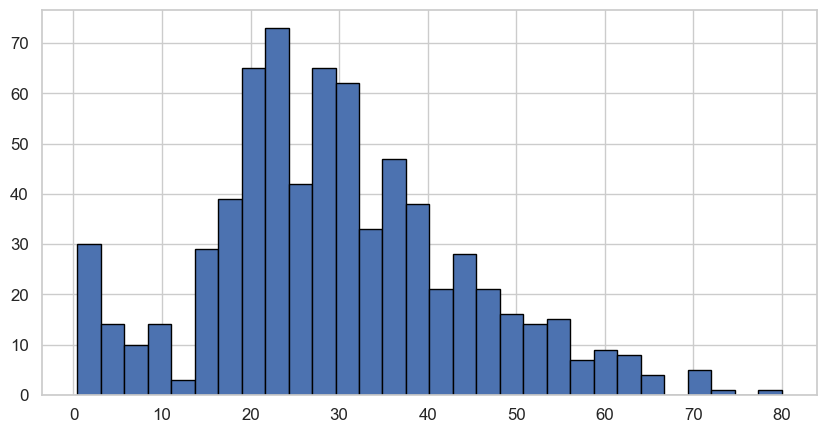

In [119]:
train_data["Age"].hist(bins=30, edgecolor="black", figsize=(10, 5))

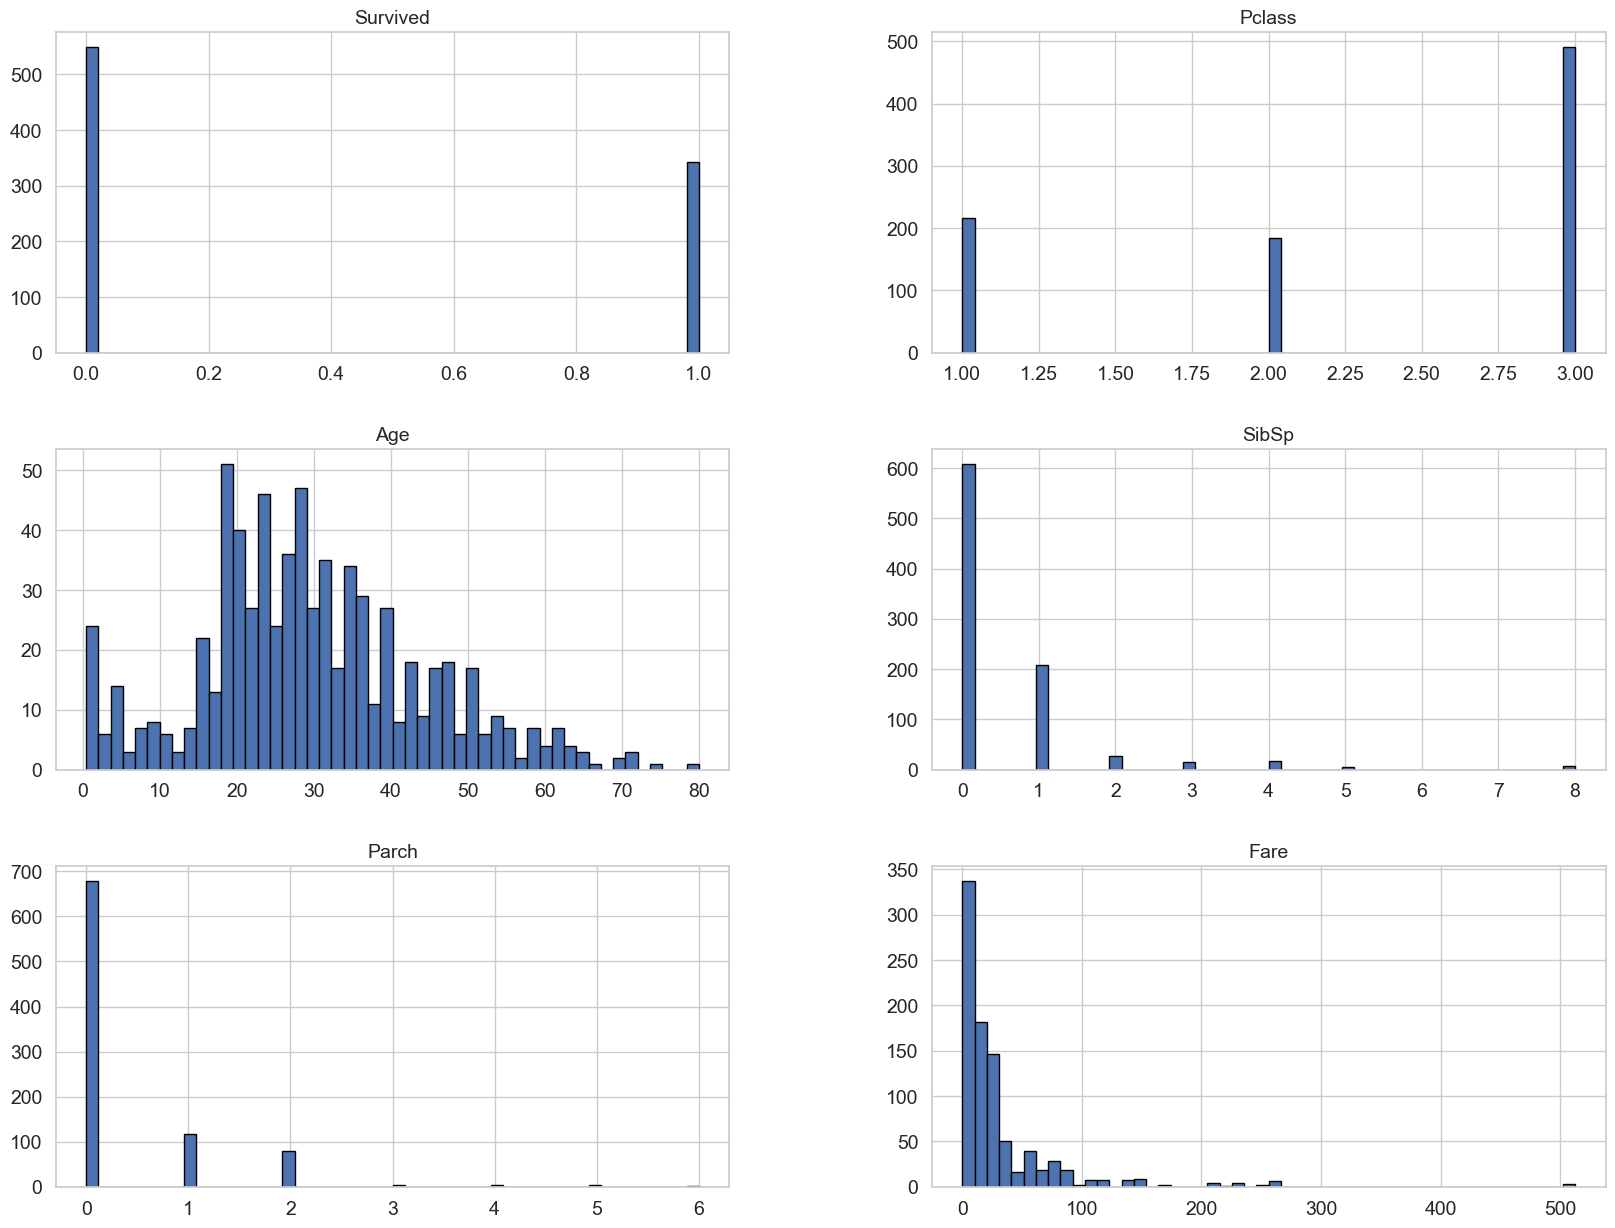

In [120]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)

train_data.hist(bins=50, edgecolor="black", figsize=(20, 15))
plt.show()

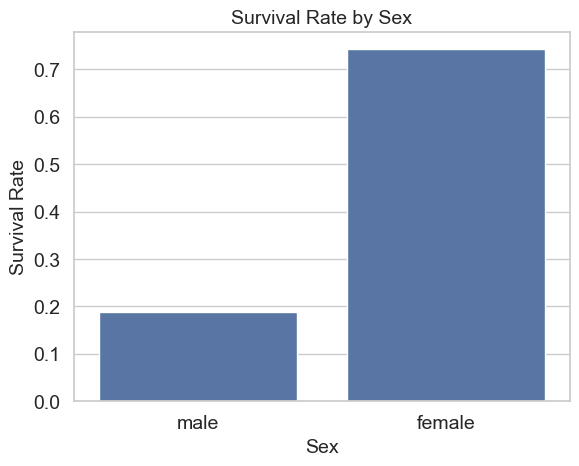

In [121]:
sns.barplot(data=train_data, x="Sex", y="Survived", errorbar=None)
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.show()

In [122]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    font_scale=1.1
)

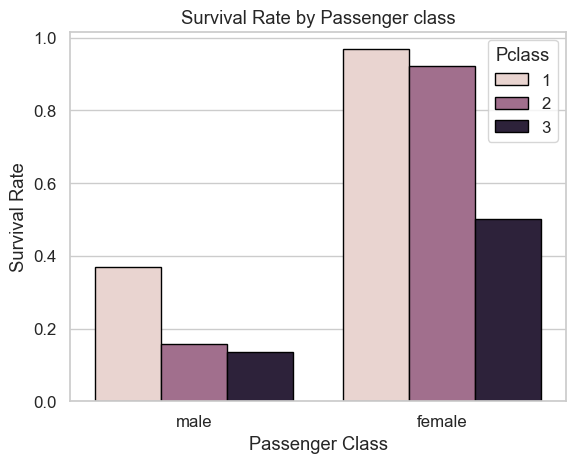

In [123]:
sns.barplot(
    data=train_data, 
    x="Sex", 
    y="Survived", 
    hue="Pclass", 
    errorbar=None,
    edgecolor="black"
)

plt.title("Survival Rate by Passenger class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

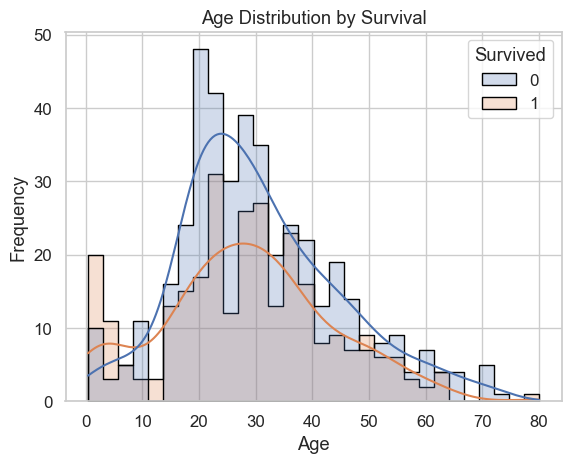

In [124]:
sns.histplot(
    data=train_data,
    x="Age",
    hue="Survived",
    bins=30,
    element="step",
    edgecolor="black",
    kde=True # Kernel Density Estimate
)

plt.ylabel("Frequency")
plt.title("Age Distribution by Survival")
plt.show()

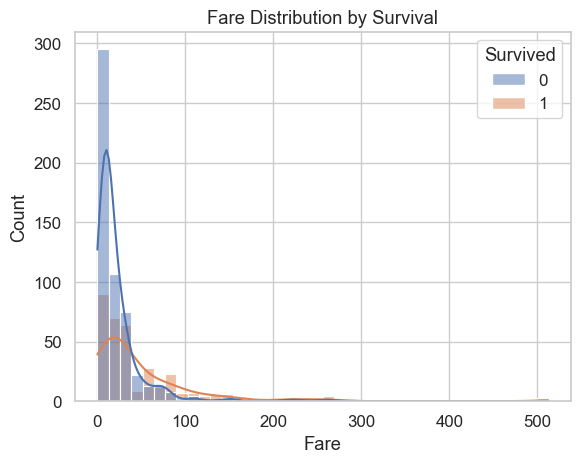

In [125]:
sns.histplot(
    data=train_data,
    x="Fare",
    hue="Survived",
    bins=40,
    kde=True
)
plt.title("Fare Distribution by Survival")
plt.show()

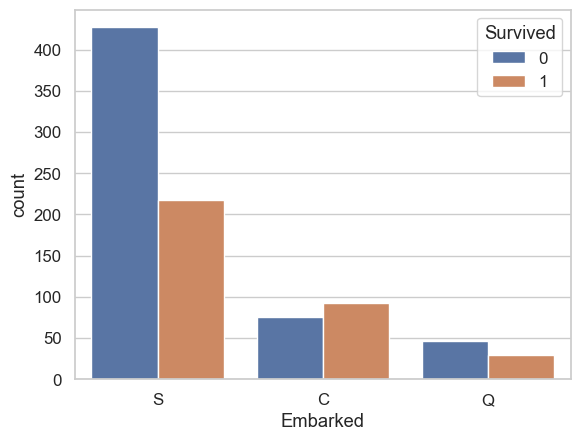

In [126]:
# Embarked distribution
sns.countplot(
    data=train_data,
    x="Embarked",
    hue="Survived"
)

plt.show()

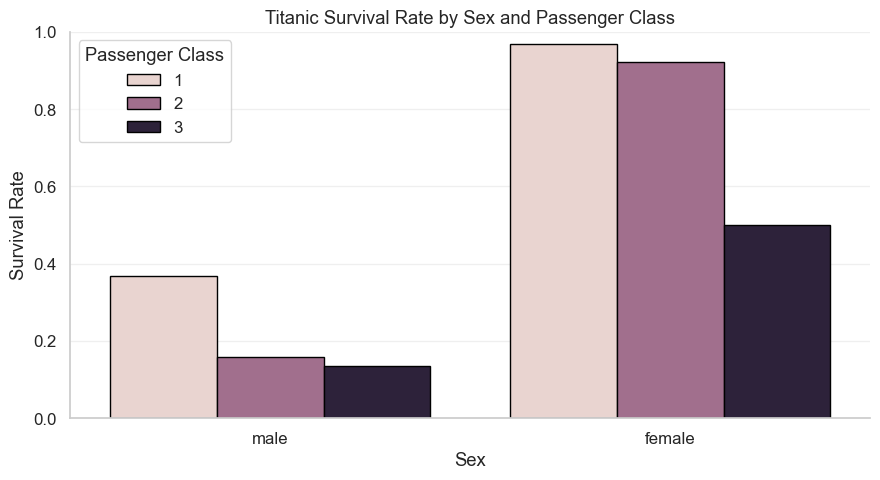

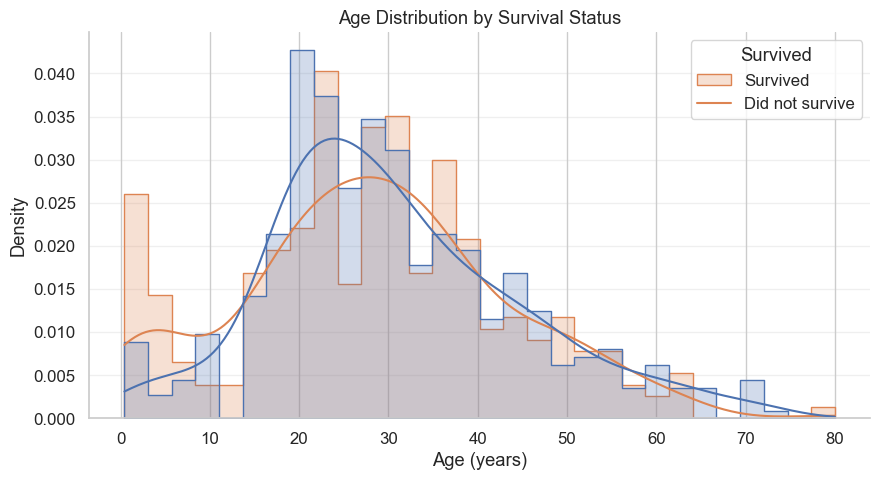

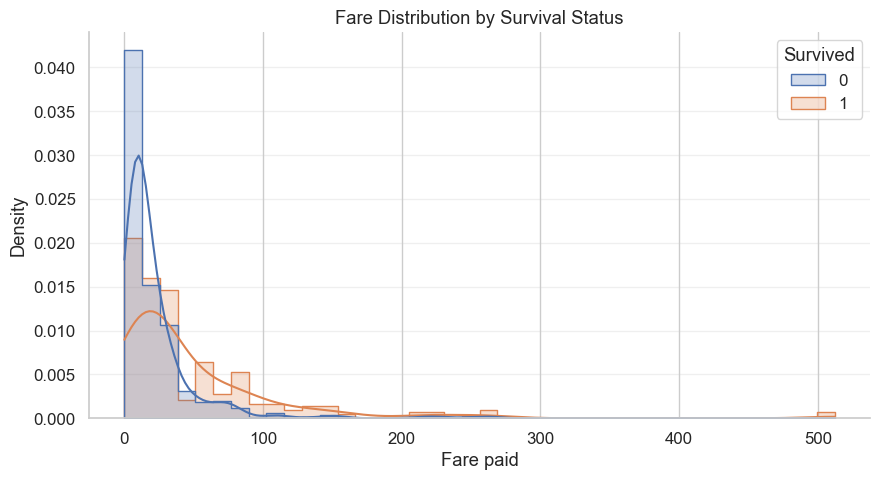

In [127]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    font_scale=1.1
)

# 1. Survival rate by sex and passenger class
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=train_data,
    x="Sex",
    y="Survived",
    hue="Pclass",
    errorbar=None,
    edgecolor="black",
    ax=ax
)

ax.set(
    title="Titanic Survival Rate by Sex and Passenger Class",
    xlabel="Sex",
    ylabel="Survival Rate",
    ylim=(0, 1)
)
ax.legend(title="Passenger Class")
ax.grid(axis="y", alpha=0.3)
sns.despine()
plt.tight_layout()
save_fig("survival_rate_by_sex_and_class")
plt.show()


# 2. Age distribution by survival
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=train_data,
    x="Age",
    hue="Survived",
    bins=30,
    element="step",
    stat="density",
    common_norm=False,
    kde=True,
    ax=ax
)

ax.set(
    title="Age Distribution by Survival Status",
    xlabel="Age (years)",
    ylabel="Density"
)
ax.legend(
    title="Survived",
    labels=["Survived", "Did not survive"]
)
ax.grid(axis="y", alpha=0.3)
sns.despine()
plt.tight_layout()
save_fig("age_distribution_by_survival_status")
plt.show()


# 3. Fare distribution by survival
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=train_data,
    x="Fare",
    hue="Survived",
    bins=40,
    element="step",
    stat="density",
    common_norm=False,
    kde=True,
    ax=ax
)

ax.set(
    title="Fare Distribution by Survival Status",
    xlabel="Fare paid",
    ylabel="Density"
)
ax.grid(axis="y", alpha=0.3)
sns.despine()
plt.tight_layout()
save_fig("fare_distribution_by_survival_status")
plt.show()


_How do the input features relate to one another_

# Age vs Pclass
Do age distributions differ by class?

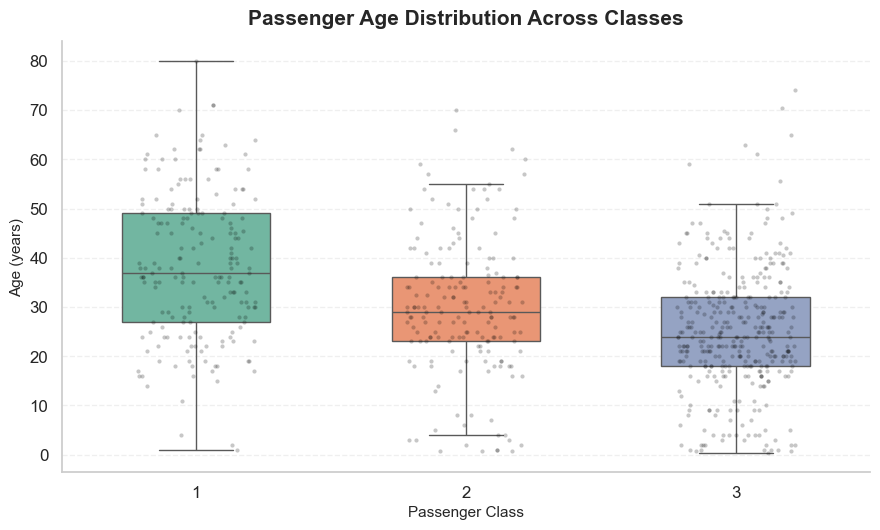

In [128]:

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.boxplot(
    data=train_data,
    x="Pclass",
    y="Age",
    hue="Pclass",
    palette="Set2",
    legend=False,
    showfliers=False,
    width=0.55,
    ax=ax
)

sns.stripplot(
    data=train_data,
    x="Pclass",
    y="Age",
    color="black",
    alpha=0.22,
    jitter=0.22,
    size=3,
    ax=ax
)

ax.set_title("Passenger Age Distribution Across Classes",
             fontsize=15, weight="bold", pad=12)
ax.set_xlabel("Passenger Class", fontsize=11)
ax.set_ylabel("Age (years)", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
save_fig("Passenger Age Distribution Across Classes")
plt.show()


# Fare vs Pclass
How does fare vary across classes?

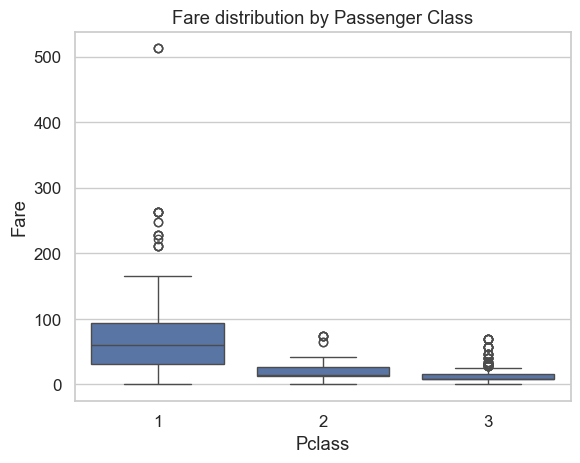

In [129]:
sns.boxplot(
    data=train_data,
    x="Pclass",
    y="Fare",

)

plt.title("Fare distribution by Passenger Class")
plt.show()

# SibSp vs Parch
Passengers traveling with siblings/spouses also are travelling with parents/children in most cases

C:\Users\DanieHKombe\AppData\Local\Temp\ipykernel_18144\3595728327.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


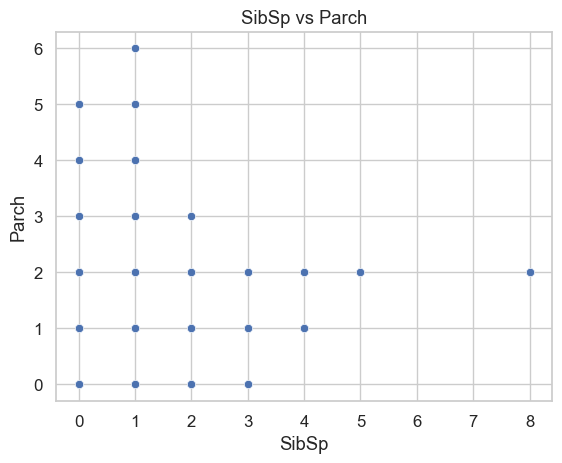

In [130]:
sns.scatterplot(
    data=train_data,
    x="SibSp",
    y="Parch",
    palette="deep",
)
plt.title("SibSp vs Parch")
plt.show()

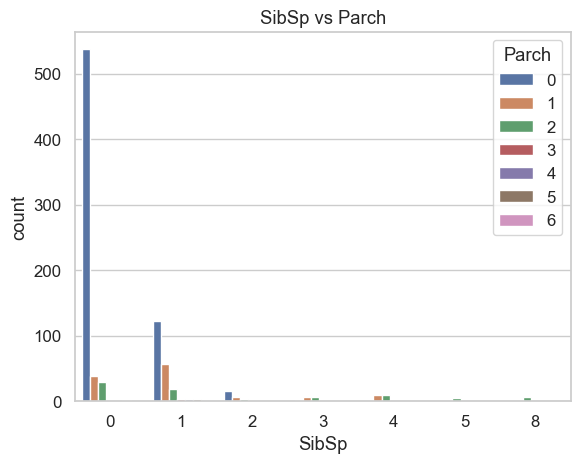

In [131]:
sns.countplot(
    data=train_data,
    x="SibSp",
    hue="Parch",
    palette="deep",
)
plt.title("SibSp vs Parch")
plt.show()

In [132]:
train_data[["SibSp", "Parch"]].corr()

,SibSp,Parch
SibSp,1.000000,0.414838
Parch,0.414838,1.000000


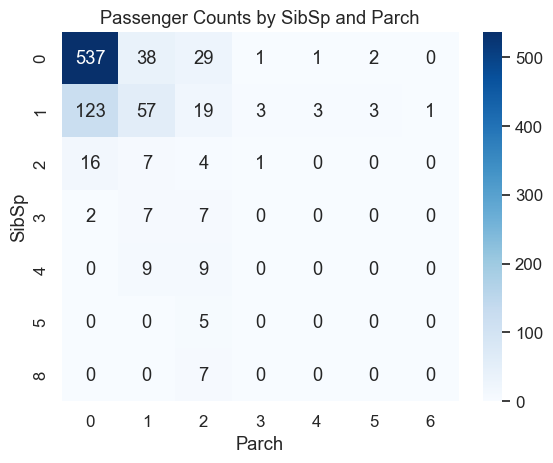

In [133]:
sns.heatmap(
    train_data.pivot_table(
        index="SibSp",
        columns="Parch",
        values="Survived",
        aggfunc="size",
        fill_value=0
    ),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Passenger Counts by SibSp and Parch")
plt.show()

# Embarked vs Pclass
Does the passenger-class distributions vary by port?

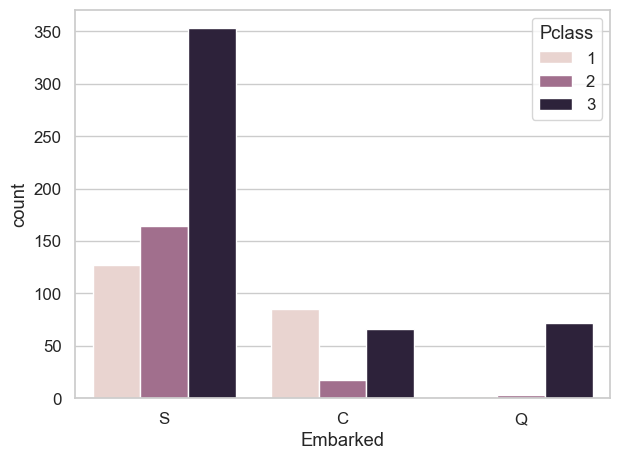

In [134]:
sns.countplot(
    data=train_data,
    x="Embarked",
    hue="Pclass"
)

save_fig("embarked vs pclass")
plt.show()

Most people boarding in port S were in class 3. As for port C some that boarded in port C were in classes 1 and 3. And as for port Q, a majority were in class 3 and none for class 1

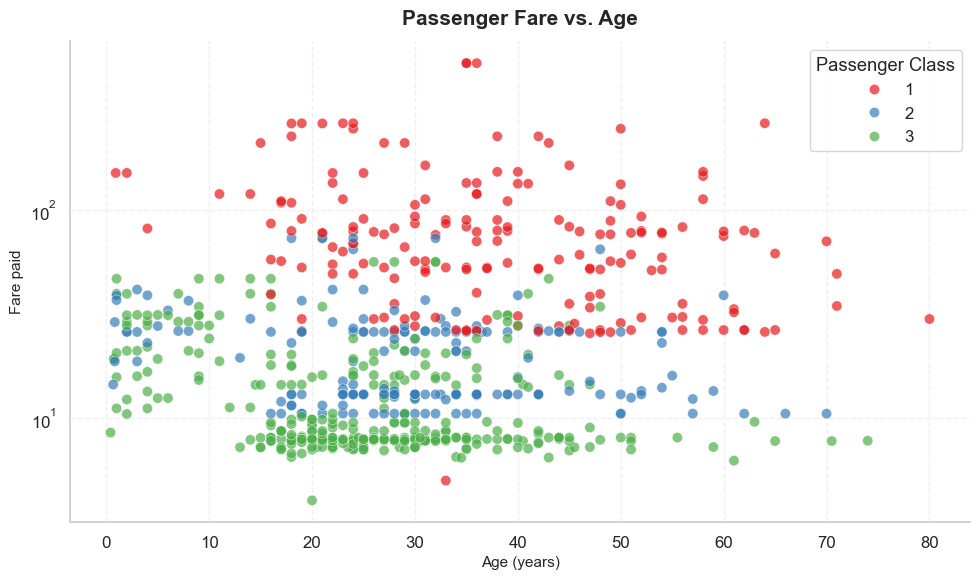

In [135]:

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=train_data,
    x="Age",
    y="Fare",
    hue="Pclass",
    palette="Set1",
    alpha=0.7,
    s=55,
    edgecolor="white",
    linewidth=0.4,
    ax=ax
)

ax.set_title("Passenger Fare vs. Age",
             fontsize=15, weight="bold", pad=12)
ax.set_yscale("log")
ax.set_xlabel("Age (years)", fontsize=11)
ax.set_ylabel("Fare paid", fontsize=11)
ax.legend(title="Passenger Class", frameon=True)
ax.grid(linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
save_fig("passenger_fare_vs_age")
plt.show()


In [136]:
corr_matrix = train_data.corr(numeric_only=True)
corr_matrix[target].sort_values(ascending=False)

Survived    1.000000
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.077221
Pclass     -0.338481
Name: Survived, dtype: float64

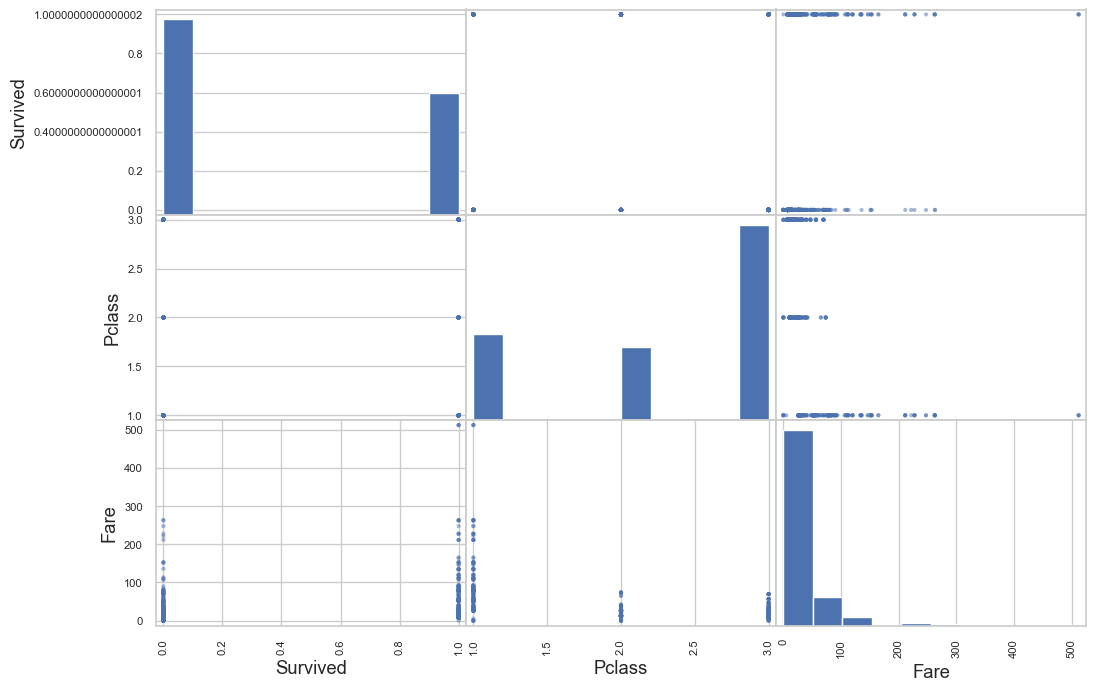

In [137]:
from pandas.plotting import scatter_matrix

attributes = corr_matrix[corr_matrix[target].abs() > 0.1].index.tolist()

# a correlation threshold of 0.1 doesn't necessarily identify the most useful 
# features. Pearson correlation measures linear association. It can miss 
# nonlinear relationships and doesn't adequately capture all relationships 
# involving categorical variables.

scatter_matrix(train_data[attributes], figsize=(12, 8))
plt.show()

A scatter matrix works best when you're examining relationships betweeen continuous numerical variables

In [138]:
survived_age = train_data[train_data["Survived"] == 1]["Age"]

# Feature Engineering

In [139]:
titanic = train_data.copy()

In [140]:
titanic["FamilySize"] = titanic["SibSp"] + titanic["Parch"] + 1

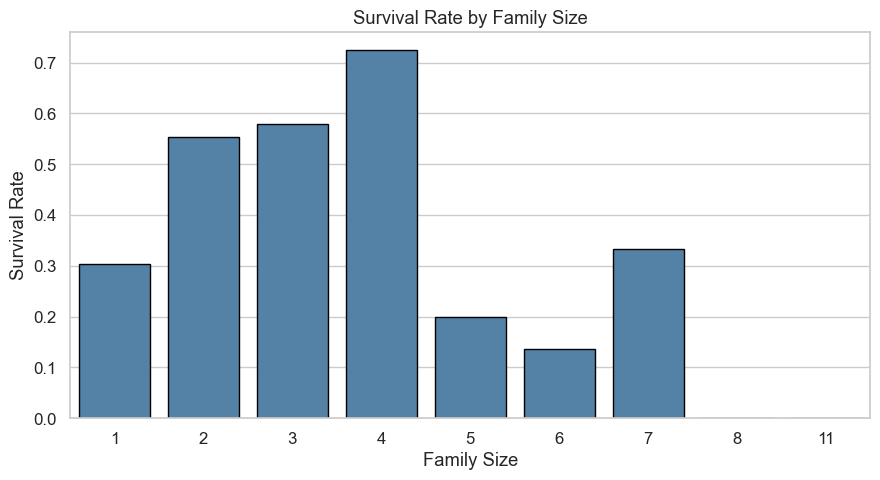

In [141]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=titanic,
    x="FamilySize",
    y="Survived",
    errorbar=None,
    color="steelblue",
    edgecolor="black",
    ax=ax
)

ax.set_title("Survival Rate by Family Size")
ax.set_xlabel("Family Size")
ax.set_ylabel("Survival Rate")
plt.tight_layout()
save_fig("Survival Rate by Family Size")
plt.show()

Test survival rates based off Passenger titles:
Mr.
Mrs.
Miss.
Master.
Dr.

In [142]:
titanic["Title"] = train_data["Name"].str.extract(r",\s*([^.]*)\.")

In [143]:
titanic["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

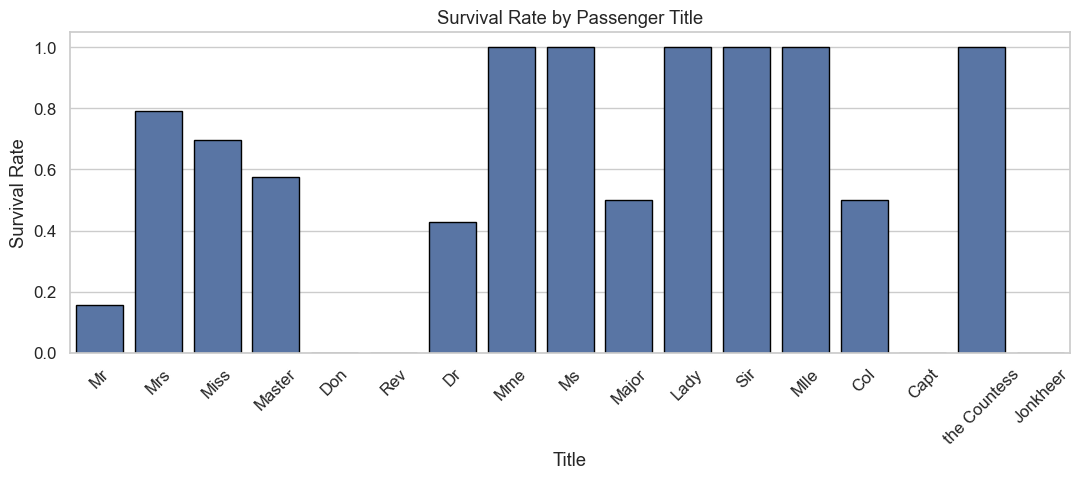

In [144]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=titanic,
    x="Title",
    y="Survived",
    errorbar=None,
    edgecolor="black"
)

plt.title("Survival Rate by Passenger Title")
plt.xlabel("Title")
plt.ylabel("Survival Rate")
plt.xticks(rotation=45)
plt.tight_layout()
save_fig("Survival rate by passenger titles")
plt.show()

In [145]:
titanic["IsAlone"] = (
    titanic["FamilySize"] == 1
).astype(int)

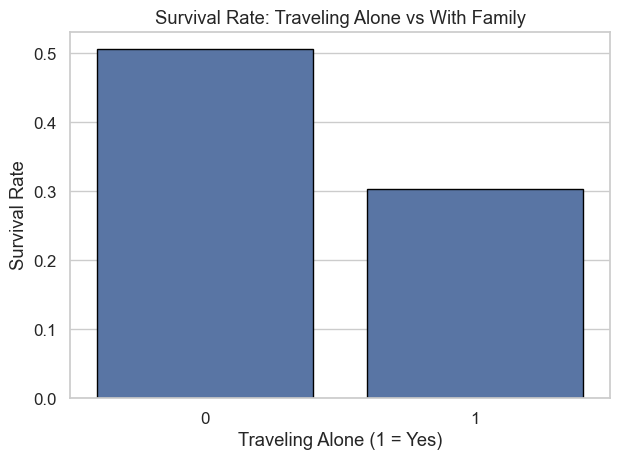

In [147]:
sns.barplot(
    data=titanic,
    x="IsAlone",
    y="Survived",
    errorbar=None,
    edgecolor="black"
)

plt.title("Survival Rate: Traveling Alone vs With Family")
plt.xlabel("Traveling Alone (1 = Yes)")
plt.ylabel("Survival Rate")
save_fig("Survival rate: Traveling Alone vs With Family")
plt.show()

In [148]:
corr_matrix = titanic.corr(numeric_only=True)
corr_matrix[target].sort_values(ascending=False)

Survived      1.000000
Fare          0.257307
Parch         0.081629
FamilySize    0.016639
SibSp        -0.035322
Age          -0.077221
IsAlone      -0.203367
Pclass       -0.338481
Name: Survived, dtype: float64

In [149]:
titanic["Deck"] = train_data["Cabin"].str[0].fillna("Unknown")

In [150]:
titanic["Deck"].value_counts(dropna=False)

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [151]:
titanic["Deck"].isna().mean() * 100

np.float64(0.0)

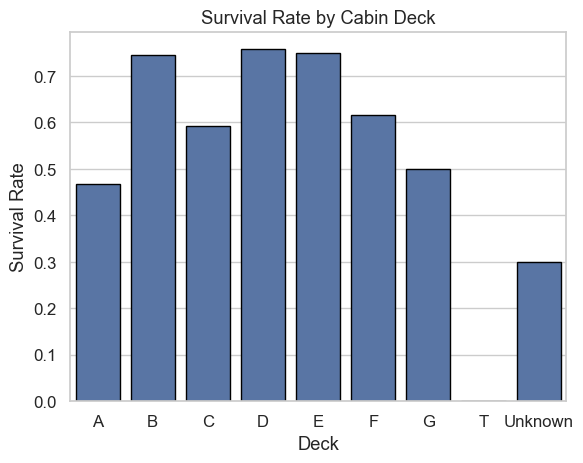

In [152]:
sns.barplot(
    data=titanic,
    x="Deck",
    y="Survived",
    errorbar=None,
    order=sorted(titanic["Deck"].dropna().unique()),
    edgecolor="black"
)

plt.title("Survival Rate by Cabin Deck")
plt.xlabel("Deck")
plt.ylabel("Survival Rate")
plt.show()

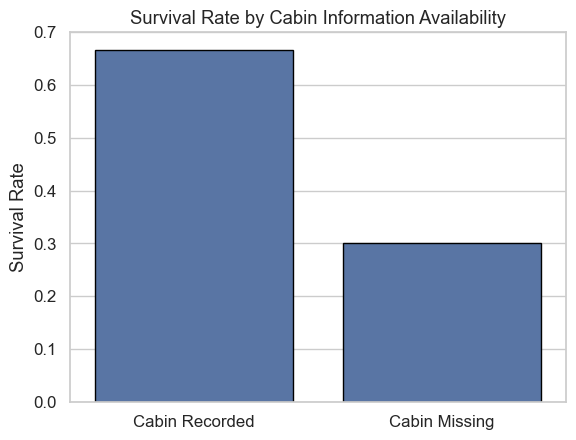

In [153]:
titanic["CabinMissing"] = titanic["Cabin"].isna().astype(int)

sns.barplot(
    data=titanic,
    x="CabinMissing",
    y="Survived",
    errorbar=None,
    edgecolor="black"
)

plt.xticks([0, 1], ["Cabin Recorded", "Cabin Missing"])
plt.title("Survival Rate by Cabin Information Availability")
plt.xlabel("")
plt.ylabel("Survival Rate")
plt.show()

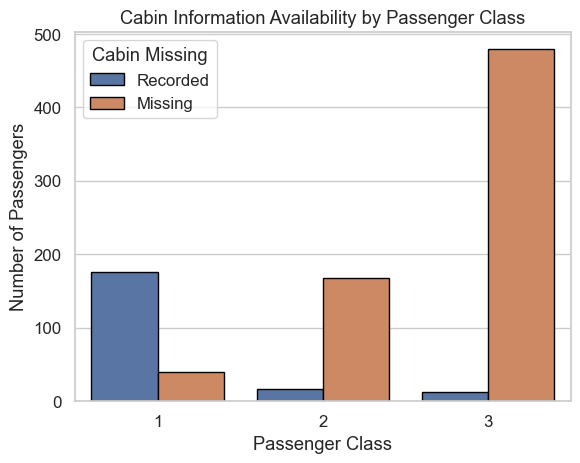

In [154]:
sns.countplot(
    data=titanic,
    x="Pclass",
    hue="CabinMissing",
    edgecolor="black"
)

plt.title("Cabin Information Availability by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(
    title="Cabin Missing",
    labels=["Recorded", "Missing"]
)
plt.show()

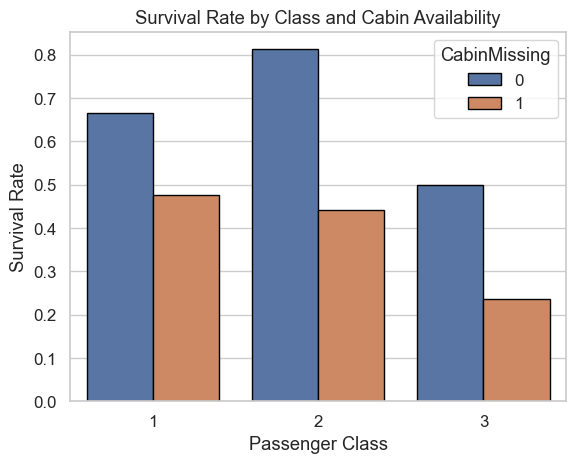

In [155]:
sns.barplot(
    data=titanic,
    x="Pclass",
    y="Survived",
    hue="CabinMissing",
    errorbar=None,
    edgecolor="black"
)

plt.title("Survival Rate by Class and Cabin Availability")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

# Handling Missing Values and Encoding -> pipeline

In [156]:
print("Mean:", train_data["Age"].mean())
print("Median:", train_data["Age"].median())
print("Skewness:", train_data["Age"].skew())

Mean: 29.69911764705882
Median: 28.0
Skewness: 0.38910778230082704


In [157]:
titanic.drop(columns=["Cabin"], inplace=True)

In [158]:
def feature_engineering(df):
    df = df.copy()


    # Family Size
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    # Title
    df["Title"] = train_data["Name"].str.extract(r",\s*([^.]*)\.")

    # isAlone
    df["IsAlone"] = (
    df["FamilySize"] == 1
    ).astype(int)

    # Cabin Deck
    df["Deck"] = df["Cabin"].str[0].fillna("Unknown")

    # Cabin missing indicator
    df["CabinMissing"] = df["Cabin"].isna().astype(int)
    
    df.drop(columns=["Cabin"], inplace=True)

    return df

In [180]:
train_prep = feature_engineering(train_data)
test_prep = feature_engineering(test_data)


num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# cat_pipeline = Pipeline([
#         ("ordinal_encoder", OrdinalEncoder()),    
#         ("imputer", SimpleImputer(strategy="most_frequent")),
#         ("cat_encoder", OneHotEncoder(sparse_output=False)),
# ])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("cat_encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

deck_pipeline = Pipeline([
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


cat_attribs = ["Pclass", "Sex", "Embarked", "Deck"]
num_attribs = (titanic.drop(columns=cat_attribs + [target] + ["IsAlone"])
               .select_dtypes(include=["int64", "float64"])
               .columns.to_list()
)

preprocess_pipeline = ColumnTransformer([
        ("num", num_pipeline, num_attribs),
        ("cat", cat_pipeline, cat_attribs),
        ("deck", deck_pipeline, ["Deck"]),
    ])

In [181]:
print(num_attribs)

['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'CabinMissing']


In [182]:
X_train = preprocess_pipeline.fit_transform(train_prep.drop(columns=[target]))
X_train

array([[-0.56573646,  0.43279337, -0.47367361, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.66386103,  0.43279337, -0.47367361, ...,  0.        ,
         0.        ,  0.        ],
       [-0.25833709, -0.4745452 , -0.47367361, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [-0.1046374 ,  0.43279337,  2.00893337, ...,  0.        ,
         0.        ,  1.        ],
       [-0.25833709, -0.4745452 , -0.47367361, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.20276197, -0.4745452 , -0.47367361, ...,  0.        ,
         0.        ,  1.        ]], shape=(891, 32))

In [183]:
y_train = train_prep[target]

In [184]:
forest_clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

forest_clf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [185]:
X_test = preprocess_pipeline.transform(test_prep)
y_pred = forest_clf.predict(X_test)

In [186]:
rmf_scores = cross_val_score(forest_clf, X_train, y_train, cv=10)
rmf_scores.mean()

np.float64(0.8024968789013732)

In [ ]:
svm_clf = SVC(gamma="auto")
svm_scores = cross_val_score(svm_clf, X_train, y_train, cv=10)
svm_scores.mean()

np.float64(0.8170661672908863)

In [196]:
svm_clf.fit(X_train, y_train)
y_pred_svc = svm_clf.predict(X_test)

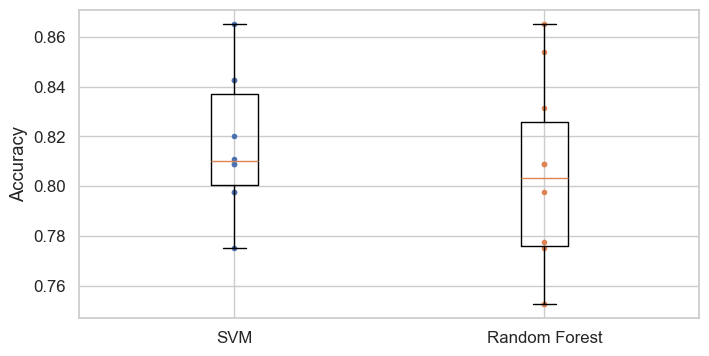

In [189]:
plt.figure(figsize=(8, 4))
plt.plot([1]*10, svm_scores, ".")
plt.plot([2]*10, rmf_scores, ".")
plt.boxplot([svm_scores, rmf_scores])
plt.xticks([1, 2], ["SVM", "Random Forest"])
plt.ylabel("Accuracy")
plt.show()

In [195]:
submission_rmf = pd.DataFrame({
    "PassengerId": test_data.index,
    "Survived": y_pred
})

submission_rmf.to_csv("submission_rmf.csv", index=False)

In [197]:
submission_svc = pd.DataFrame({
    "PassengerId": test_data.index,
    "Survived": y_pred_svc
})

submission_svc.to_csv("submission_svc.csv", index=False)

In [ ]:
submission_rmf

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


In [198]:
submission_svc

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0
